In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

In [2]:
df = pd.read_csv("churn_cleaned.csv")
df.shape

(7032, 20)

In [3]:
y = df['Churn'].map({'No': 0, 'Yes': 1})
X = pd.get_dummies(df.drop(columns=['Churn']), drop_first=True, dtype=int)

X.shape

(7032, 30)

## Data Preparation

- The target is **Churn** (0 = stayed, 1 = left). The features are the other 19 columns.
- Models need numbers, so each text column was converted into 0/1 columns using one-hot encoding. This turned 19 features into **30 columns**.
- `drop_first=True` removes one redundant column per category, which avoids duplicated information.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print("Churn rate in train:", round(y_train.mean(), 3))
print("Churn rate in test:", round(y_test.mean(), 3))

(5625, 30) (1407, 30)
Churn rate in train: 0.266
Churn rate in test: 0.266


## Train/Test Split

- The data was split into **5,625 customers for training (80%)** and **1,407 for testing (20%)**.
- The model learns only from the training set and is judged on the test set, which it has never seen. This shows whether it works on new customers and not just on data it memorized.
- The split is **stratified**: the churn rate is 26.6% in both sets, so they are comparable.
- `random_state=42` makes the results repeatable.

In [5]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

## Feature Scaling

- Features were standardized so that columns on different scales (tenure up to 72, monthly charges up to about 119) are treated fairly by logistic regression.
- The scaler was fitted on the training data only and then applied to the test data, to avoid leaking information from the test set.
- Random forest does not need scaling, so it uses the original data.

In [6]:
def evaluate(name, y_true, pred, prob):
    print(name)
    print("Accuracy :", round(accuracy_score(y_true, pred), 3))
    print("Precision:", round(precision_score(y_true, pred), 3))
    print("Recall   :", round(recall_score(y_true, pred), 3))
    print("F1 score :", round(f1_score(y_true, pred), 3))
    print("ROC-AUC  :", round(roc_auc_score(y_true, prob), 3))
    print("Confusion matrix:")
    print(confusion_matrix(y_true, pred))

In [7]:
log_model = LogisticRegression(max_iter=1000, class_weight='balanced')
log_model.fit(X_train_sc, y_train)

log_pred = log_model.predict(X_test_sc)
log_prob = log_model.predict_proba(X_test_sc)[:, 1]

evaluate("Logistic Regression", y_test, log_pred, log_prob)

Logistic Regression
Accuracy : 0.726
Precision: 0.491
Recall   : 0.797
F1 score : 0.608
ROC-AUC  : 0.835
Confusion matrix:
[[724 309]
 [ 76 298]]


## Model 1: Logistic Regression

| Metric | Result |
|---|---|
| Accuracy | 72.6% |
| Precision | 49.1% |
| Recall | 79.7% |
| F1 score | 0.608 |
| ROC-AUC | 0.835 |

**Confusion matrix:** Of the 374 customers who actually left, the model correctly caught **298** and missed **76**. It also flagged **309** customers who stayed, which are false alarms.

**What this means:** The model catches about **8 out of 10** customers who are going to leave. About half of the customers it flags actually leave (precision 49%), so a retention team using it would contact some customers who were not at risk.

**Why class_weight='balanced':** Only about 27% of customers churn, so a model could reach about 73% accuracy by predicting that nobody leaves. Balancing the classes forces the model to look for the churners, which trades some accuracy for much higher recall.

In [8]:
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=8, class_weight='balanced',
    random_state=42
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

evaluate("Random Forest", y_test, rf_pred, rf_prob)

Random Forest
Accuracy : 0.751
Precision: 0.521
Recall   : 0.775
F1 score : 0.623
ROC-AUC  : 0.838
Confusion matrix:
[[766 267]
 [ 84 290]]


## Model 2: Random Forest

| Metric | Result |
|---|---|
| Accuracy | 75.1% |
| Precision | 52.1% |
| Recall | 77.5% |
| F1 score | 0.623 |
| ROC-AUC | 0.838 |

**Confusion matrix:** Of the 374 customers who actually left, the model caught **290** and missed **84**. It flagged **267** customers who stayed.

**What this means:** The model catches about **7.8 out of 10** churners, with fewer false alarms than logistic regression (267 vs 309). Trees were limited to a depth of 8 to stop the model from memorizing the training data.

## Comparing the Two Models

- The models perform almost the same overall: ROC-AUC is **0.835** for logistic regression and **0.838** for random forest.
- **Logistic regression** catches 8 more churners (298 vs 290) but creates 42 more false alarms (309 vs 267).
- **Random forest** has higher accuracy (75.1% vs 72.6%) and precision (52.1% vs 49.1%).
- The better choice depends on the business. If missing a customer who leaves is very costly and retention offers are cheap, favor higher recall (logistic regression). If retention offers are expensive, favor fewer false alarms (random forest).

**Limitations:** Results come from a single train/test split and the models were not tuned. Both are a baseline that could be improved.

In [9]:
# Comparison table
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, log_pred), accuracy_score(y_test, rf_pred)],
    'Precision': [precision_score(y_test, log_pred), precision_score(y_test, rf_pred)],
    'Recall': [recall_score(y_test, log_pred), recall_score(y_test, rf_pred)],
    'F1': [f1_score(y_test, log_pred), f1_score(y_test, rf_pred)],
    'ROC-AUC': [roc_auc_score(y_test, log_prob), roc_auc_score(y_test, rf_prob)]
}).round(3)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.726,0.491,0.797,0.608,0.835
1,Random Forest,0.751,0.521,0.775,0.623,0.838


## Model Comparison

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 72.6% | 49.1% | 79.7% | 0.608 | 0.835 |
| Random Forest | 75.1% | 52.1% | 77.5% | 0.623 | 0.838 |

**Observation:** The two models perform almost the same. Their ROC-AUC scores differ by only 0.003, which means both separate customers who leave from customers who stay equally well. Random forest is slightly ahead on accuracy, precision and F1, while logistic regression is slightly ahead on recall (it catches about 2 more out of every 100 churners).

**Decision:** I choose **[Logistic Regression / Random Forest]** because [reason, see below].

**Why the metric matters:** Only about 27% of customers churn, so accuracy alone can be misleading. Recall (how many real churners we catch) and precision (how many flagged customers really churn) matter more for a retention campaign.

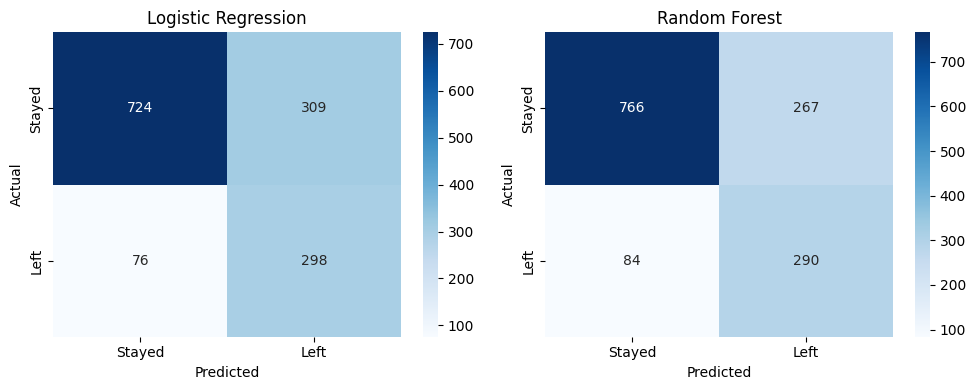

In [10]:
# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [('Logistic Regression', log_pred), ('Random Forest', rf_pred)]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Stayed', 'Left'], yticklabels=['Stayed', 'Left'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

## Confusion Matrices

Both matrices use the same 1,407 test customers: 1,033 who stayed and 374 who left.

| | Logistic Regression | Random Forest |
|---|---|---|
| Correctly predicted to stay | 724 | 766 |
| Wrongly flagged as leaving (false alarms) | 309 | 267 |
| Missed churners (predicted to stay, but left) | 76 | 84 |
| Correctly caught churners | 298 | 290 |

**How to read it:** The top row shows customers who actually stayed, and the bottom row shows customers who actually left. The bottom-right square (customers who left and were correctly caught) is the one that matters most for a retention team.

**Observation:**
- Logistic regression catches **298 of 374** churners (79.7%) and misses 76.
- Random forest catches **290 of 374** churners (77.5%) and misses 84.
- Both models flag some customers who would have stayed: 309 for logistic regression and 267 for random forest, meaning about 1 in 4 to 1 in 3 customers who stay get wrongly flagged.

**Why it matters:** Each missed churner is lost revenue, while each false alarm costs only the price of a retention offer. Because losing a customer usually costs more than a discount, catching more churners is worth some false alarms. That is why recall is the key metric here.

**Trade-off:** Logistic regression catches 8 more churners but creates 42 more false alarms than random forest. Which is better depends on how expensive a retention offer is compared with the value of a retained customer.


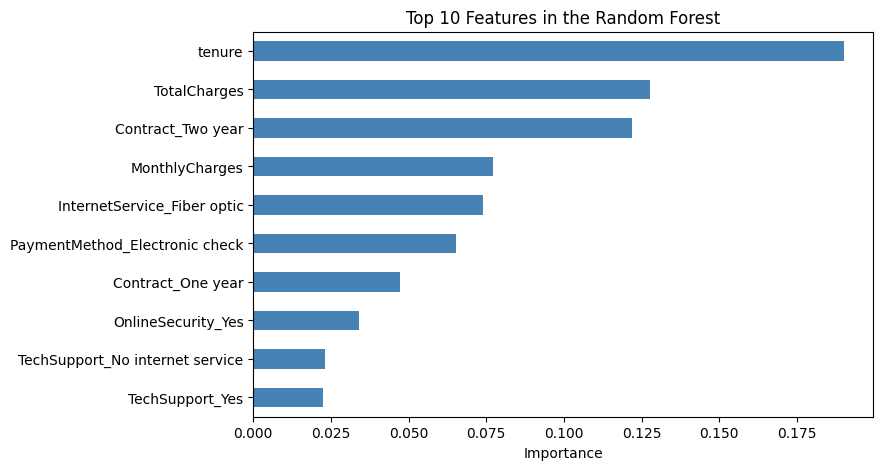

tenure                             0.190
TotalCharges                       0.128
Contract_Two year                  0.122
MonthlyCharges                     0.077
InternetService_Fiber optic        0.074
PaymentMethod_Electronic check     0.065
Contract_One year                  0.047
OnlineSecurity_Yes                 0.034
TechSupport_No internet service    0.023
TechSupport_Yes                    0.022
dtype: float64


In [11]:
# What drives the random forest's predictions
imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
imp.sort_values().plot(kind='barh', color='steelblue')
plt.title("Top 10 Features in the Random Forest")
plt.xlabel("Importance")
plt.show()

print(imp.round(3))

## Feature Importance (Random Forest)

| Rank | Feature | Importance |
|---|---|---|
| 1 | tenure | 0.190 |
| 2 | TotalCharges | 0.128 |
| 3 | Contract_Two year | 0.122 |
| 4 | MonthlyCharges | 0.077 |
| 5 | InternetService_Fiber optic | ~0.074 |
| 6 | PaymentMethod_Electronic check | ~0.065 |
| 7 | Contract_One year | ~0.047 |
| 8 | OnlineSecurity_Yes | ~0.034 |
| 9 | TechSupport_No internet service | ~0.023 |
| 10 | TechSupport_Yes | ~0.022 |

**Observation:** Tenure is the most important feature (**0.190**), followed by total charges (**0.128**) and a two-year contract (**0.122**). The top 3 features alone account for about 44% of the model's total importance, and the top 10 for roughly 78%.

**How this matches my EDA findings:**
- **Tenure** was the strongest numeric link with churn (correlation -0.35), and first-year customers churned at 47.7%.
- **Contract type** (two-year and one-year) matches the huge gap between month-to-month (42.7%) and two-year contracts (2.8%).
- **Fiber optic** and **electronic check** are the same groups I found with churn rates of 41.9% and 45.3%.
- **Online security and tech support** match my finding that customers without add-on services churn about 3 times more.
- **Monthly charges** matches my finding that churned customers pay higher bills.

**Why it matters:** The model relies on the same factors my analysis found, so its predictions are explainable and consistent with the data. The retention team can focus on new customers, month-to-month contracts, fiber optic users and electronic check payers.

**Limitations:**
- Importance shows which features the model uses, not whether they raise or lower churn. For direction, I rely on the EDA results.
- Tenure and total charges are strongly related (0.83), so their importance is shared between them.
- TechSupport_No internet service is the same group of customers as having no internet service, so it reflects that group, not a separate effect.